# 1. Analyze a dataset (6 points) 
The Pima Indian Diabetes Dataset used in this project is proposed by npradaschnor (2019) in github.

The Pima Indian Diabetes Dataset, originally from the National Institute of Diabetes and Digestive and Kidney Diseases, contains information of 768 women from a population near Phoenix, Arizona, USA. The outcome tested was Diabetes, 258 tested positive and 500 tested negative. Therefore, there is one target (dependent) variable and the 8 attributes (TYNECKI, 2018): 
- pregnancies, 
- OGTT(Oral Glucose Tolerance Test), 
- blood pressure, 
- skin thickness, 
- insulin, 
- BMI(Body Mass Index), 
- age,
-  pedigree diabetes function.



In [54]:
!git clone https://github.com/npradaschnor/Pima-Indians-Diabetes-Dataset.git

12258.83s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


fatal: destination path 'Pima-Indians-Diabetes-Dataset' already exists and is not an empty directory.


In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn import preprocessing

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV

In [56]:
df=pd.read_csv("Pima-Indians-Diabetes-Dataset/diabetes.csv")
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


The data looks clean. No null value in all entries.

## Exploratory Data Analysis (EDA)

I'm going to use histogram and box plot as EDA techniques for better understanding our data.

### Univariate Analysis
Hhistograms are chosen to display all features's distribution, because all features are numeric values in the dataset. `Glucose`, `BloodPressure`, `BMI`, and `DiabetesPerdegeeFunction` are likely normal distribution. The dependent variable, `outcome`, is binary, with `Outcome=0` standing for no diabetes, and `Outcome=1` standing for diabetes. 

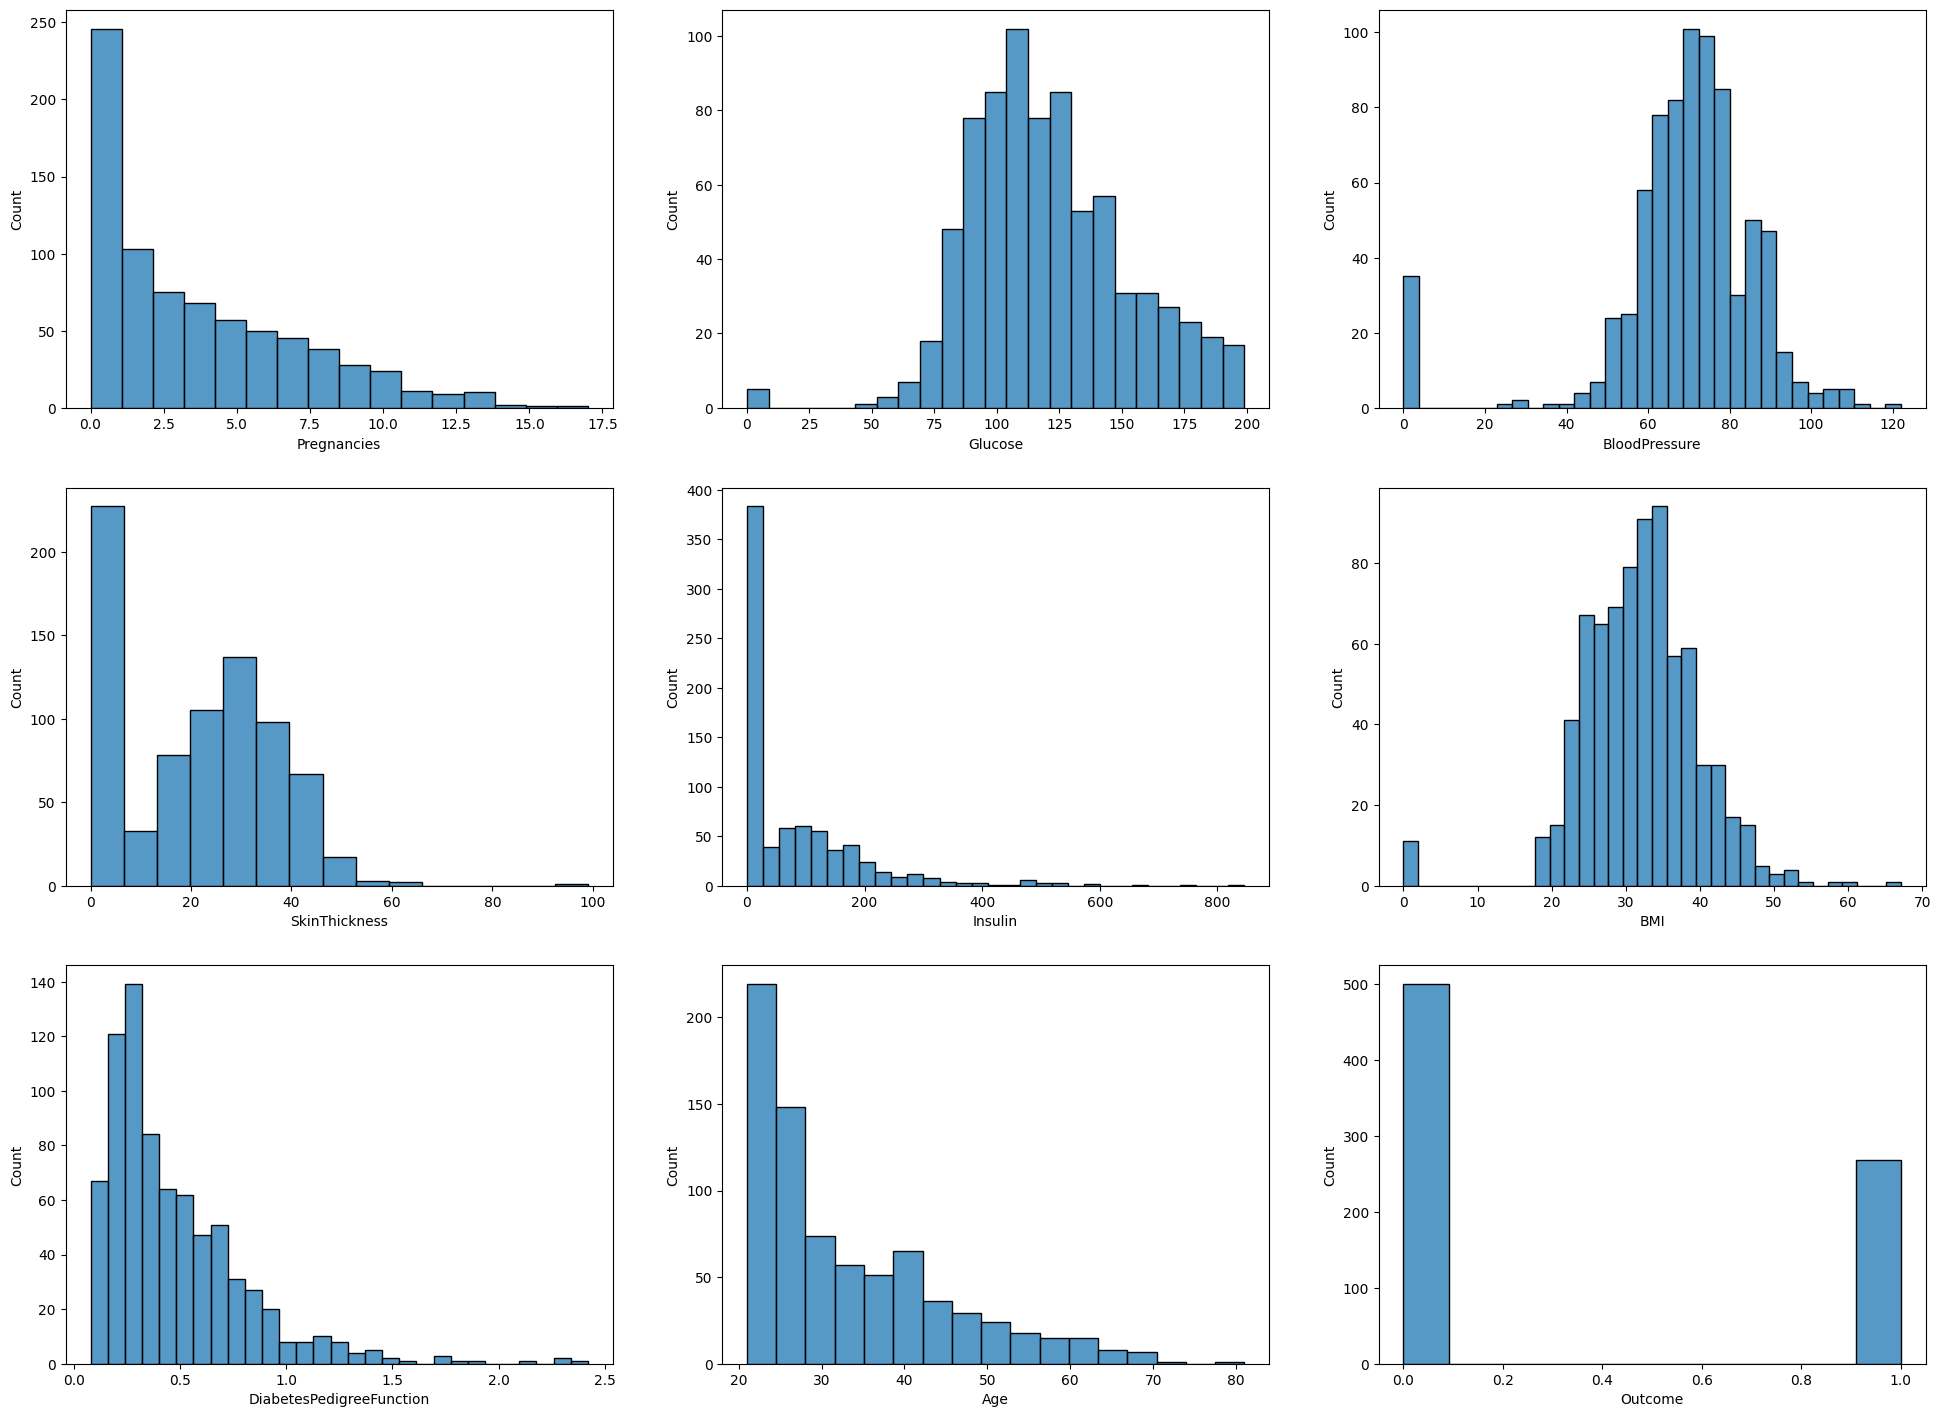

In [58]:
fig= plt.figure(figsize=(24, 30))
count=0
for column in df.columns:
  subfigure=fig.add_subplot(5,3,count+1)
  subfigure.set_xlabel(column)
  sns.histplot(data=df, x=df[column]) # Using seaborn histogram visualization
  count+=1

### Numeric features vs. outcome
A box plot helps visualize how numerical feature values differ across different outcome groups. It can be observed in the plots below that the feature `Glucose` shows a clear distinction between `Outcome = 0` and `Outcome = 1`, indicating its potential importance as a predictor of diabetes. In contrast, features like `Skin thickness` and `Blood pressure` display similar distributions across the target categories, suggesting they may be less influential in predicting the outcome.

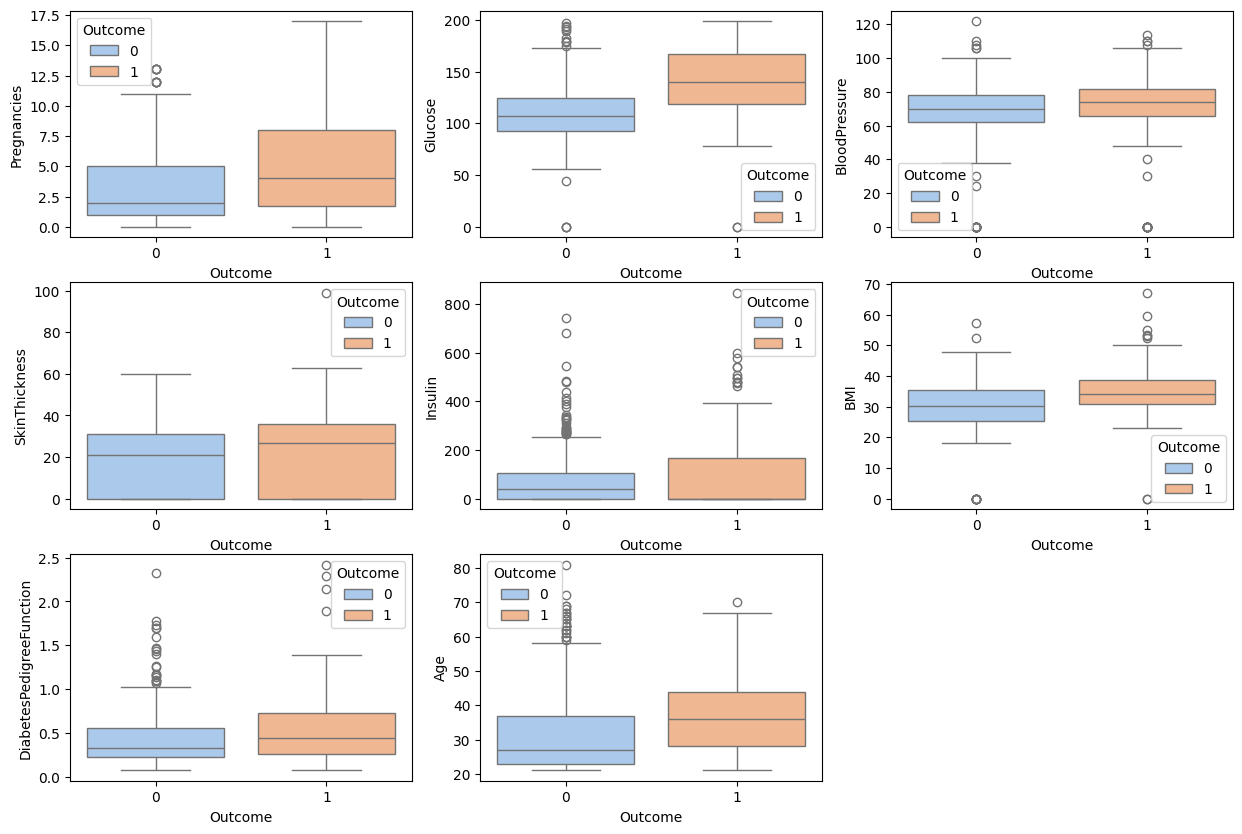

In [59]:
fig = plt.figure(figsize=(15,10))
features = df.columns[:-1]

for i in range(len(features)):
  sub=fig.add_subplot(3,3, i+1)
  sns.boxplot(x='Outcome', y=features[i], data=df, palette='pastel', hue='Outcome') # Using seaborn's boxplot visualization

# 2. Train a binary classifier (5 points)

## Split Dataset into Training and Testing Set
Split the dataset into a training and test set so you can train your model on one portion of the data and evaluate it on another. 

In [60]:
X = df.drop(['Outcome'], axis=1)
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=97)

print(f"Training data shape: X={X_train.shape}, Y={y_train.shape}")
print(f"Test data shape: X={X_test.shape}, Y={y_test.shape}")

Training data shape: X=(614, 8), Y=(614,)
Test data shape: X=(154, 8), Y=(154,)


##  Train a baseline model. 
Logistic regression, SVC, KNN, Decision tree, random fores and gaussian Naive Bayes are added to the model pipeline. The models are trained and evaluated. Accuracy, AUC, precision, recall and F1 score are used to measure the performance of the classifier.

Naive Bayes is the best model overall. It achieves the highest Accuracy and F1 score, while maintaining high Precision and Recall score. In **medical scenarios** like predicting diabetes, **Recall (the ability to identify all actual positive cases)** is typically prioritized to minimize false negatives, making Naive Bayes the clear winner.

However, this doesn't necessarily mean that Naive Bayes is universally better algorithms. It simply indicates that it's better suited for this particular dataset, which is relatively small and contains features on different scales.

In [61]:
model_pipeline = [] # Declaring empty pipeline
model_pipeline.append(LogisticRegression(solver='liblinear'))
model_pipeline.append(SVC())
model_pipeline.append(KNeighborsClassifier())
model_pipeline.append(DecisionTreeClassifier())
model_pipeline.append(RandomForestClassifier())
model_pipeline.append(GaussianNB())

# Declaring empty lists to store performance metrics of each model
accuracy_list=[]
AUC_list=[]
confusion_matrix_list=[]
precision_list=[]
recall_list=[]
f1_score_list=[]

for model in model_pipeline:
  model.fit(X_train, y_train) # Training the model
  y_pred = model.predict(X_test) # Making predictions on the test set
  accuracy_list.append(round(metrics.accuracy_score(y_test, y_pred),2)) # Adding accuracy of the model to the accuracy list
  false_positive_rate, true_positive_rate, _threshold = metrics.roc_curve(y_test, y_pred)
  AUC_list.append(round(metrics.auc(false_positive_rate, true_positive_rate),2))
  confusion_matrix_list.append(confusion_matrix(y_test, y_pred))
  precision_list.append(round(metrics.precision_score(y_test, y_pred),2))
  recall_list.append(round(metrics.recall_score(y_test, y_pred),2))
  f1_score_list.append(round(metrics.f1_score(y_test, y_pred),2))

model_list=['Logistic regression', 'SVM', 'KNN', 'Decision Tree', 'Random Forest', 'Naive Bayes']
result_df=pd.DataFrame({'Model':model_list,
                        'Accuracy': accuracy_list,
                        #'AUC':AUC_list,
                        'Precision': precision_list,
                        'Recall': recall_list,
                        'F1 Score': f1_score_list})
result_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic regression,0.79,0.85,0.51,0.64
1,SVM,0.77,0.82,0.49,0.62
2,KNN,0.72,0.67,0.49,0.57
3,Decision Tree,0.73,0.65,0.58,0.61
4,Random Forest,0.77,0.78,0.54,0.64
5,Naive Bayes,0.79,0.80,0.58,0.67


# Improve the model’s performance (4 points) 
Perform feature selection and hyperparameter tuning.

In [62]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline

# define models and parameters
model = GaussianNB()

n_features = X.shape[1]

# Candidate numbers of features
# 2, 3, 8
candidate_k = sorted({
    max(1, int(np.sqrt(n_features))),
    max(1, int(np.log2(n_features))),
    n_features
})

pipeline = Pipeline([
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("model", GaussianNB())
])

parameter_grid = {
    "feature_selection__k": candidate_k,
   }

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted"
}

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=1001
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    cv=cv,
    scoring=scoring,
    refit="recall",              # Select the best model based on recall
    n_jobs=-1,
    error_score="raise"
)

grid_result = grid_search.fit(X, y)


# Display the selected feature names
best_selector = grid_result.best_estimator_.named_steps["feature_selection"]
selected_features = X.columns[best_selector.get_support()]

print("Selected features:")
print(selected_features.tolist())

results = grid_result.cv_results_

for i, params in enumerate(results["params"]):
    print(f"\nParameters: {params}")
    print(
        f"Accuracy:  {results['mean_test_accuracy'][i]:.4f} "
        f"(+/- {results['std_test_accuracy'][i]:.4f})"
    )
    print(
        f"Precision: {results['mean_test_precision'][i]:.4f} "
        f"(+/- {results['std_test_precision'][i]:.4f})"
    )
    print(
        f"Recall:    {results['mean_test_recall'][i]:.4f} "
        f"(+/- {results['std_test_recall'][i]:.4f})"
    )
    print(
        f"F1 score:  {results['mean_test_f1'][i]:.4f} "
        f"(+/- {results['std_test_f1'][i]:.4f})"
    )

Selected features:
['Glucose', 'BMI']

Parameters: {'feature_selection__k': 2}
Accuracy:  0.7652 (+/- 0.0168)
Precision: 0.7609 (+/- 0.0182)
Recall:    0.7652 (+/- 0.0168)
F1 score:  0.7543 (+/- 0.0193)

Parameters: {'feature_selection__k': 3}
Accuracy:  0.7600 (+/- 0.0242)
Precision: 0.7547 (+/- 0.0247)
Recall:    0.7600 (+/- 0.0242)
F1 score:  0.7528 (+/- 0.0242)

Parameters: {'feature_selection__k': 8}
Accuracy:  0.7534 (+/- 0.0224)
Precision: 0.7498 (+/- 0.0234)
Recall:    0.7534 (+/- 0.0224)
F1 score:  0.7501 (+/- 0.0229)


The feature selection step selects `glucose` and `BMI` as the most impactful feature combinations, which is also suggested in previous exploratory analysis.
The CV selects the best model based on recall score, as previous discussed. After feature selection, NB model highly improves Recall and F1 score, with recall score =    0.7652 (+/- 0.0168), F1 score =  0.7543 (+/- 0.0193).

In [63]:
X_selected = X.loc[:, selected_features]

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=1001
)

coarse_grid = {
    "var_smoothing": np.logspace(-12, 1, num=100)
}

coarse_search = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=coarse_grid,
    cv=cv,
    scoring=scoring,
    refit="recall",
    n_jobs=-1,
    error_score="raise",
)

coarse_result = coarse_search.fit(X_selected, y)

best_smoothing = coarse_result.best_params_["var_smoothing"]

results = coarse_result.cv_results_

/opt/anaconda3/envs/proj6002/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/envs/proj6002/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/envs/proj6002/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(resu

In [64]:
print("\nBest parameters:", best_smoothing)
best_index = coarse_result.best_index_

print("Recall-selected parameters:", results["params"][best_index])
print(
    f"Accuracy of the recall-selected model: "
    f"{results['mean_test_accuracy'][best_index]:.4f}"
)
print(
    f"Best cross-validated recall: "
    f"{results['mean_test_recall'][best_index]:.4f}"
)
print(
    f"Precision: {results['mean_test_precision'][best_index]:.4f}"
)
print(
    f"F1 score: {results['mean_test_f1'][best_index]:.4f}"
)



Best parameters: 1e-12
Recall-selected parameters: {'var_smoothing': np.float64(1e-12)}
Accuracy of the recall-selected model: 0.7652
Best cross-validated recall: 0.7652
Precision: 0.7609
F1 score: 0.7543


The performance after fine-tuning `var_smooth` doesn't change. The default `var_smooth` is already optimal.

**Reference**
The project draws on the course material *Module 7: Classification Model Pipeline*, particularly the sessions on `Exploratory Data Analysis (EDA)` and `Model Training and Evaluation`.

**AI usage**
Visual Studio Code Copilot was used to assist in drafting the code for training the Gaussian Naive Bayes classifier. However, the generated code was not directly runnable (InvalidIndexError) and did not fully satisfy the project requirements. For example, the project require seperately feature selection and hyperparameter fine-tune, which is not realized in copilot's code.

Using the Copilot-generated code as an initial reference, together with the course material *Module 7: Classification Model Pipeline*, I independently revised and rewrote the implementation to ensure that it was executable and aligned with the specific project requirements. All written content, including the explanations, comments, figures, reports, and README, was independently created by me. The original prompt and Copilot's output are provided below.

**Prompt**: perform feature selection to gaussian NB model

**Output**: Read skill `python-fact-grounded-coding`

I’ll inspect the full selected notebook cell and verify the scikit-learn parameter names so the feature-selection step is valid rather than treating `features` as a GaussianNB parameter.

Read , lines 1 to 26
Completed with input: {
  "path": "/Users/...",
  "view_range": [
    1,
    26
  ]
}

pylanceRunCodeSnippet
Completed with input: {
  "codeSnippet": "from sklearn.naive_bayes import GaussianNB\nfrom sklearn.model_selection import GridSearchCV\nfrom sklearn.feature_selection import SelectKBest, f_classif\nfrom sklearn.pipeline import Pipeline\n\npipe = Pipeline([('selector', SelectKBest(score_func=f_classif)), ('model', GaussianNB())])\nprint(sorted(pipe.get_params().keys()))",
  "workingDirectory": "/Users/...",
  "workspaceRoot": "/Users/..."
}

`features` is not a valid `GaussianNB` parameter. Put feature selection in a `Pipeline`, then tune the selector’s `k` parameter together with `GaussianNB`’s `var_smoothing`.

```python
import numpy as np

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

n_features = X.shape[1]

# Candidate numbers of features
candidate_k = sorted({
    max(1, int(np.sqrt(n_features))),
    max(1, int(np.log2(n_features))),
    n_features
})

pipeline = Pipeline([
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("model", GaussianNB())
])

parameter_grid = {
    "feature_selection__k": candidate_k,
    "model__var_smoothing": np.logspace(0, -9, num=100)
}

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=1001
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    n_jobs=-1,
    cv=cv,
    scoring="accuracy",
    error_score="raise"
)

grid_result = grid_search.fit(X, y)

print(f"Best accuracy: {grid_result.best_score_:.4f}")
print(f"Best parameters: {grid_result.best_params_}")

# Display the selected feature names
best_selector = grid_result.best_estimator_.named_steps["feature_selection"]
selected_features = X.columns[best_selector.get_support()]

print("Selected features:")
print(selected_features.tolist())
```

The important parameter names are:

```python
"feature_selection__k"
"model__var_smoothing"
```

The double underscore tells `GridSearchCV` to tune parameters inside the pipeline. Using the pipeline also ensures that feature selection is performed separately inside each cross-validation fold, avoiding data leakage.

The selected notebook snapshot is read-only, so it was not modified. The available Pylance interpreter also does not currently have `scikit-learn` installed, so the cell could not be executed in that environment.